In [1]:
import configparser
import json
import os
import re

import joblib
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import shap
from venn import venn

In [2]:
os.chdir('../')

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('data.ini')
data = data['DEFAULT']

In [4]:
with open(data['ml'] + 'tools_features_selection.json', 'r') as file:
    features_selections = json.load(file)

features_selections_genes = {}
for key, value in features_selections.items():
    features_selections_genes[key] = value['genes']

# maxmif HN - onlyRAS_onlyNonRAS

In [5]:
onlyRAS = set(features_selections_genes['maxmif HN - onlyRAS'])
onlyNonRAS = set(features_selections_genes['maxmif HN - onlyRAS_onlyNonRAS']) - onlyRAS
len(onlyRAS), len(onlyNonRAS)

(443, 2042)

## mutclust

In [6]:
suffix = 'TCGA_tran&mut_["mutclust - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'maxmif HN - onlyRAS_onlyNonRAS'

model_LR_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegression.joblib')
model_lSVM_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/linearSVM.joblib')
model_pSVM_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/polynomialSVM.joblib')
model_LRl_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegressionLasso.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_maxmifHN_mutclust = json.load(f)

train_RAS = pd.read_csv(f'{inputDir}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS = pd.read_csv(f'{inputDir}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS = pd.read_csv(f'{inputDir}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS = pd.read_csv(f'{inputDir}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_maxmifHN_mutclust = scaler.transform(pd.concat([train_RAS, train_nonRAS])[info_maxmifHN_mutclust['valid_features_train']])
test_maxmifHN_mutclust = scaler.transform(pd.concat([test_RAS, test_nonRAS])[info_maxmifHN_mutclust['valid_features_train']])

In [7]:
weights_LR = pd.DataFrame({'feature': info_maxmifHN_mutclust['valid_features_train'], 'weight': model_LR_maxmifHN_mutclust.coef_[0]}).sort_values('weight', ascending=False)
weights_LRl = pd.DataFrame({'feature': info_maxmifHN_mutclust['valid_features_train'], 'weight': model_LRl_maxmifHN_mutclust.coef_[0]}).sort_values('weight', ascending=False)
weights_lSVM = pd.DataFrame({'feature': info_maxmifHN_mutclust['valid_features_train'], 'weight': model_lSVM_maxmifHN_mutclust.coef_[0]}).sort_values('weight', ascending=False)

importance_maxmifHN_mutclust_LR_lRL = pd.merge(weights_LR, weights_LRl, on='feature', how='inner', suffixes=[' LR', ' LRl']).rename(columns={'weight LR': 'LR weight', 'weight LRl': 'LRl weight'})
importance_maxmifHN_mutclust = pd.merge(importance_maxmifHN_mutclust_LR_lRL, weights_lSVM, on='feature', how='inner').rename(columns={'weight': 'lSVM weight'})
importance_maxmifHN_mutclust['gene'] = importance_maxmifHN_mutclust['feature'].str.split('_').str[0]
importance_maxmifHN_mutclust['from'] = importance_maxmifHN_mutclust['gene'].apply(lambda x: 'RAS' if x in onlyRAS else ('nonRAS' if x in onlyNonRAS else '-'))

cols = list(importance_maxmifHN_mutclust.columns)
cols.insert(1, cols.pop(cols.index('gene')))
cols.insert(2, cols.pop(cols.index('from')))
importance_maxmifHN_mutclust = importance_maxmifHN_mutclust[cols]

numerical_cols = importance_maxmifHN_mutclust.select_dtypes(include=['number']).columns
importance_maxmifHN_mutclust[numerical_cols] = importance_maxmifHN_mutclust[numerical_cols].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_mutclust['sum'] = importance_maxmifHN_mutclust[numerical_cols].sum(axis=1)
importance_maxmifHN_mutclust[['sum']] = importance_maxmifHN_mutclust[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_mutclust = importance_maxmifHN_mutclust.sort_values('sum', ascending=False)

In [8]:
importance_maxmifHN_mutclust

,feature,gene,from,LR weight,LRl weight,lSVM weight,sum
1,HOXB7_tran,HOXB7,RAS,0.859841,0.839301,1.000000,1.000000
0,TFRC_noCluster,TFRC,nonRAS,1.000000,0.653211,0.831274,0.920472
4,KCNN4_tran,KCNN4,nonRAS,0.707630,1.000000,0.764205,0.915785
2,HOXB3_tran,HOXB3,nonRAS,0.783165,0.761539,0.896918,0.904592
3,DGKG_tran,DGKG,nonRAS,0.757431,0.727984,0.829387,0.857606
...,...,...,...,...,...,...,...
4685,RHEB_noCluster,RHEB,nonRAS,-0.723278,-0.285917,-0.829736,-0.681302
4686,CPS1_814_833,CPS1,nonRAS,-0.732211,-0.354270,-0.836993,-0.712624
4684,NFKBIZ_noCluster,NFKBIZ,nonRAS,-0.713776,-0.604054,-0.841163,-0.799881
4687,CEP350_noCluster,CEP350,nonRAS,-0.817405,-0.734700,-0.931176,-0.920026


In [9]:
plot_LR_maxmifHN_mutclust = pd.DataFrame(
    [(i, len(importance_maxmifHN_mutclust.loc[importance_maxmifHN_mutclust['LR weight'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_mutclust['LR weight'].max(), importance_maxmifHN_mutclust['LR weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

plot_lSVM_maxmifHN_mutclust = pd.DataFrame(
    [(i, len(importance_maxmifHN_mutclust.loc[importance_maxmifHN_mutclust['lSVM weight'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_mutclust['lSVM weight'].max(), importance_maxmifHN_mutclust['lSVM weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

plot_LRl_maxmifHN_mutclust = pd.DataFrame(
    [(i, len(importance_maxmifHN_mutclust.loc[importance_maxmifHN_mutclust['LRl weight'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_mutclust['LRl weight'].max(), importance_maxmifHN_mutclust['LRl weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

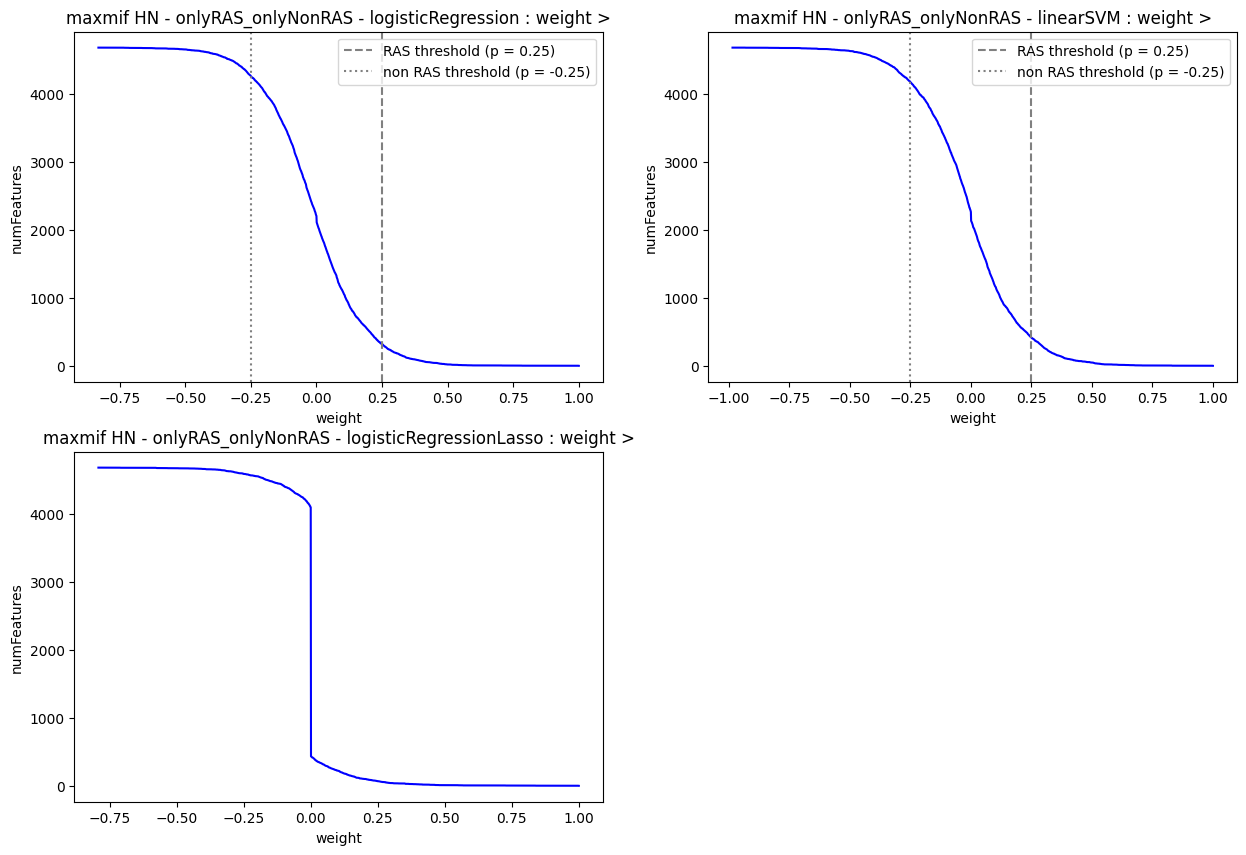

In [10]:
# plot both in different plots
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
ax = ax.flatten()

ax[0].plot(plot_LR_maxmifHN_mutclust['weight'], plot_LR_maxmifHN_mutclust['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--', label='RAS threshold (p = 0.25)')
ax[0].axvline(x=-0.25, color='grey', linestyle=':', label='non RAS threshold (p = -0.25)')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegression : weight >')
ax[0].legend()

ax[1].plot(plot_lSVM_maxmifHN_mutclust['weight'], plot_lSVM_maxmifHN_mutclust['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--', label='RAS threshold (p = 0.25)')
ax[1].axvline(x=-0.25, color='grey', linestyle=':', label='non RAS threshold (p = -0.25)')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('maxmif HN - onlyRAS_onlyNonRAS - linearSVM : weight >')
ax[1].legend()

ax[2].plot(plot_LRl_maxmifHN_mutclust['weight'], plot_LRl_maxmifHN_mutclust['numFeatures'], color='blue')
# ax[2].axvline(x=0.1, color='grey', linestyle='--')
# ax[2].axvline(x=-0.04, color='grey', linestyle=':')
ax[2].set_xlabel('weight')
ax[2].set_ylabel('numFeatures')
ax[2].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegressionLasso : weight >')

ax[3].axis('off')

# plt.suptitle('maxmif HN - onlyRAS_onlyNonRAS - mutclust')

plt.savefig('data/plots/fia/w_mutclust_thresholds.png')

#### significant features

In [11]:
RAS_significantFeatures_LR_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LR weight'] > 0.25]['feature'])
RAS_significantFeatures_lSVM_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['lSVM weight'] > 0.25]['feature'])
RAS_significantFeatures_LRl_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LRl weight'] > 0]['feature'])

len(RAS_significantFeatures_LR_maxmifHN_mutclust), len(RAS_significantFeatures_lSVM_maxmifHN_mutclust), len(RAS_significantFeatures_LRl_maxmifHN_mutclust)

(320, 415, 437)

In [12]:
print("LR & lSVM:\t\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust))
print("LR & lSVM & LRl:\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust))

LR & lSVM:		 314
LR & LRl:		 263
lSVM & LRl:		 298
LR & lSVM & LRl:	 259


In [13]:
nonRAS_significantFeatures_LR_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LR weight'] < -0.25]['feature'])
nonRAS_significantFeatures_lSVM_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['lSVM weight'] < -0.25]['feature'])
nonRAS_significantFeatures_LRl_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LRl weight'] < 0]['feature'])

In [14]:
print("LR & lSVM:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust))

LR & lSVM:		 404
LR & LRl:		 347
lSVM & LRl:		 395
LR & lSVM & LRl:	 339


#### RAS-significant transcriptomic features

In [15]:
RAS_significantTranscriptomic_LR_maxmifHN_mutclust = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_mutclust 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_mutclust 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_LRl_maxmifHN_mutclust = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_mutclust 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust), len(RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust), len(RAS_significantTranscriptomic_LRl_maxmifHN_mutclust)

(192, 232, 220)

In [16]:
print("LR & lSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust))

LR & lSVM:		 187
LR & LRl:		 146
lSVM & LRl:		 159
LR & lSVM & LRl:	 143


In [17]:
importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['feature'].isin(RAS_significantTranscriptomic_LR_maxmifHN_mutclust & RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust & RAS_significantTranscriptomic_LRl_maxmifHN_mutclust)]

,feature,gene,from,LR weight,LRl weight,lSVM weight,sum
1,HOXB7_tran,HOXB7,RAS,0.859841,0.839301,1.000000,1.000000
4,KCNN4_tran,KCNN4,nonRAS,0.707630,1.000000,0.764205,0.915785
2,HOXB3_tran,HOXB3,nonRAS,0.783165,0.761539,0.896918,0.904592
3,DGKG_tran,DGKG,nonRAS,0.757431,0.727984,0.829387,0.857606
10,SEMA7A_tran,SEMA7A,nonRAS,0.554829,0.847652,0.619302,0.749046
...,...,...,...,...,...,...,...
270,PTPN3_tran,PTPN3,nonRAS,0.266230,0.015350,0.270162,0.204414
302,RASA2_tran,RASA2,RAS,0.254917,0.018985,0.276765,0.204015
244,GDF15_tran,GDF15,RAS,0.274800,0.014102,0.259736,0.203264
315,CDC16_tran,CDC16,RAS,0.252085,0.015163,0.265023,0.197200


#### RAS-significant mutational features

In [18]:
RAS_significantMutations_LR_maxmifHN_mutclust  = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_lSVM_maxmifHN_mutclust  = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_LRl_maxmifHN_mutclust  = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantMutations_LR_maxmifHN_mutclust), len(RAS_significantMutations_lSVM_maxmifHN_mutclust), len(RAS_significantMutations_LRl_maxmifHN_mutclust)

(128, 183, 217)

In [19]:
print("LR & lSVM:\t\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust))

LR & lSVM:		 127
LR & LRl:		 117
lSVM & LRl:		 139
LR & lSVM & LRl:	 116


In [20]:
importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['feature'].isin(RAS_significantMutations_LR_maxmifHN_mutclust & RAS_significantMutations_lSVM_maxmifHN_mutclust & RAS_significantMutations_LRl_maxmifHN_mutclust)]

,feature,gene,from,LR weight,LRl weight,lSVM weight,sum
0,TFRC_noCluster,TFRC,nonRAS,1.000000,0.653211,0.831274,0.920472
15,TAGAP_noCluster,TAGAP,RAS,0.518426,0.550244,0.639720,0.632938
7,NLRP12_noCluster,NLRP12,nonRAS,0.580424,0.394544,0.688288,0.616216
13,IL10RA_noCluster,IL10RA,RAS,0.539077,0.400165,0.585856,0.565031
19,FUS_noCluster,FUS,RAS,0.503008,0.404724,0.590079,0.554921
...,...,...,...,...,...,...,...
284,ADAMTS14_noCluster,ADAMTS14,nonRAS,0.260585,0.038774,0.294681,0.220085
319,MMP13_noCluster,MMP13,nonRAS,0.250778,0.010816,0.322000,0.216214
280,ST13_noCluster,ST13,RAS,0.262231,0.004751,0.315320,0.215736
259,DOK2_noCluster,DOK2,RAS,0.269090,0.014796,0.256623,0.200252


#### comparison with maxmif significance in RAS/nonRAS

In [21]:
RAS_significantMutGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_LR_maxmifHN_mutclust
])
RAS_significantMutGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_lSVM_maxmifHN_mutclust
])
RAS_significantMutGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_LRl_maxmifHN_mutclust
])
len(RAS_significantMutGenes_LR_maxmifHN_mutclust), len(RAS_significantMutGenes_lSVM_maxmifHN_mutclust), len(RAS_significantMutGenes_LRl_maxmifHN_mutclust)

(128, 183, 217)

In [22]:
print("LR & lSVM:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust))

LR & lSVM:		 127
LR & LRl:		 117
lSVM & LRl:		 140
LR & lSVM & LRl:	 116


In [23]:
nonRAS_significantMutations_LR_maxmifHN_mutclust  = set([
    f for f in nonRAS_significantFeatures_LR_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_lSVM_maxmifHN_mutclust  = set([
    f for f in nonRAS_significantFeatures_lSVM_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_LRl_maxmifHN_mutclust  = set([
    f for f in nonRAS_significantFeatures_LRl_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

nonRAS_significantMutGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LR_maxmifHN_mutclust
])
nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_lSVM_maxmifHN_mutclust
])
nonRAS_significantMutGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LRl_maxmifHN_mutclust
])

len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust), len(nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust), len(nonRAS_significantMutGenes_LRl_maxmifHN_mutclust)

(232, 286, 349)

In [24]:
print("LR & lSVM:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust))

LR & lSVM:		 224
LR & LRl:		 194
lSVM & LRl:		 225
LR & lSVM & LRl:	 191


In [25]:
# LR: RAS -> RAS
mc_LR_RAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyRAS]
# LR: nonRAS -> RAS
mc_LR_nonRAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyNonRAS]
# LR: RAS -> nonRAS
mc_LR_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyRAS]
# LR: nonRAS -> nonRAS
mc_LR_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyNonRAS]

len(mc_LR_RAS_RAS), len(mc_LR_nonRAS_RAS), len(mc_LR_RAS_nonRAS), len(mc_LR_nonRAS_nonRAS)

(55, 73, 5, 227)

In [26]:
# lSVM: RAS -> RAS
mc_lSVM_RAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyRAS]
# lSVM: nonRAS -> RAS
mc_lSVM_nonRAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyNonRAS]
# lSVM: RAS -> nonRAS
mc_lSVM_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyRAS]
# lSVM: nonRAS -> nonRAS
mc_lSVM_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyNonRAS]
len(mc_lSVM_RAS_RAS), len(mc_lSVM_nonRAS_RAS), len(mc_lSVM_RAS_nonRAS), len(mc_lSVM_nonRAS_nonRAS) 

(69, 114, 6, 280)

In [27]:
# LRl: RAS -> RAS
mc_LRl_RAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyRAS]
# LRl: nonRAS -> RAS
mc_LRl_nonRAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyNonRAS]
# LRl: RAS -> nonRAS
mc_LRl_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyRAS]
# LRl: nonRAS -> nonRAS
mc_LRl_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyNonRAS]
len(mc_LRl_RAS_RAS), len(mc_LRl_nonRAS_RAS), len(mc_LRl_RAS_nonRAS), len(mc_LRl_nonRAS_nonRAS)

(83, 134, 15, 334)

#### RAS-significant mutational clustered features

In [28]:
RAS_significantClusters_LR_maxmifHN_mutclust = set([
    f for f in RAS_significantMutations_LR_maxmifHN_mutclust
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_lSVM_maxmifHN_mutclust = set([
    f for f in RAS_significantMutations_lSVM_maxmifHN_mutclust
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_LRl_maxmifHN_mutclust = set([
    f for f in RAS_significantMutations_LRl_maxmifHN_mutclust
    if re.search(r'_\d+_\d+', f) 
])
len(RAS_significantClusters_LR_maxmifHN_mutclust), len(RAS_significantClusters_lSVM_maxmifHN_mutclust), len(RAS_significantClusters_LRl_maxmifHN_mutclust)

(8, 12, 14)

In [29]:
print("LR & lSVM:\t\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust))

LR & lSVM:		 8
LR & LRl:		 7
lSVM & LRl:		 9
LR & lSVM & LRl:	 7


significant clusters' genes

In [30]:
RAS_significantClusterGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LR_maxmifHN_mutclust
])
RAS_significantClusterGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_lSVM_maxmifHN_mutclust
])
RAS_significantClusterGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LRl_maxmifHN_mutclust
])
len(RAS_significantClusterGenes_LR_maxmifHN_mutclust), len(RAS_significantClusterGenes_lSVM_maxmifHN_mutclust), len(RAS_significantClusterGenes_LRl_maxmifHN_mutclust)

(8, 12, 14)

In [31]:
print("LR & lSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust))

LR & lSVM:		 8
LR & LRl:		 7
lSVM & LRl:		 9
LR & lSVM & LRl:	 7


## oncodriveclustl

In [32]:
suffix = 'TCGA_tran&mut_["oncodriveclustl_coadreadParams - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'maxmif HN - onlyRAS_onlyNonRAS'

model_LR_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegression.joblib')
model_lSVM_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/linearSVM.joblib')
model_LRl_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegressionLasso.joblib')
model_pSVM_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/polynomialSVM.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_maxmifHN_oncodriveclustl = json.load(f)

train_RAS = pd.read_csv(f'{inputDir}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS = pd.read_csv(f'{inputDir}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS = pd.read_csv(f'{inputDir}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS = pd.read_csv(f'{inputDir}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_maxmifHN_oncodriveclustl = scaler.transform(pd.concat([train_RAS, train_nonRAS])[info_maxmifHN_oncodriveclustl['valid_features_train']])
test_maxmifHN_oncodriveclustl = scaler.transform(pd.concat([test_RAS, test_nonRAS])[info_maxmifHN_oncodriveclustl['valid_features_train']])

In [33]:
weights_LR = pd.DataFrame({'feature': info_maxmifHN_oncodriveclustl['valid_features_train'], 'weight': model_LR_maxmifHN_oncodriveclustl.coef_[0]}).sort_values('weight', ascending=False)
weights_LRl = pd.DataFrame({'feature': info_maxmifHN_oncodriveclustl['valid_features_train'], 'weight': model_LRl_maxmifHN_oncodriveclustl.coef_[0]}).sort_values('weight', ascending=False)
shapValuesMean_lSVM = pd.DataFrame({'feature': info_maxmifHN_oncodriveclustl['valid_features_train'], 'weight': model_lSVM_maxmifHN_oncodriveclustl.coef_[0]}).sort_values('weight', ascending=False)

importance_maxmifHN_oncodriveclustl_LR_LRl = pd.merge(weights_LR, weights_LRl, on='feature', how='inner', suffixes=[' LR', ' LRl']).rename(columns={'weight LR': 'LR weight', 'weight LRl': 'LRl weight'})
importance_maxmifHN_oncodriveclustl = pd.merge(importance_maxmifHN_oncodriveclustl_LR_LRl, shapValuesMean_lSVM, on='feature', how='inner').rename(columns={'weight': 'lSVM weight'})
importance_maxmifHN_oncodriveclustl['gene'] = importance_maxmifHN_oncodriveclustl['feature'].str.split('_').str[0]
importance_maxmifHN_oncodriveclustl['from'] = importance_maxmifHN_oncodriveclustl['gene'].apply(lambda x: 'RAS' if x in onlyRAS else ('nonRAS' if x in onlyNonRAS else '-'))

cols = list(importance_maxmifHN_oncodriveclustl.columns)
cols.insert(1, cols.pop(cols.index('gene')))
cols.insert(2, cols.pop(cols.index('from')))
importance_maxmifHN_oncodriveclustl = importance_maxmifHN_oncodriveclustl[cols]

numerical_cols = importance_maxmifHN_oncodriveclustl.select_dtypes(include=['number']).columns
importance_maxmifHN_oncodriveclustl[numerical_cols] = importance_maxmifHN_oncodriveclustl[numerical_cols].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_oncodriveclustl['sum'] = importance_maxmifHN_oncodriveclustl[numerical_cols].sum(axis=1)
importance_maxmifHN_oncodriveclustl[['sum']] = importance_maxmifHN_oncodriveclustl[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_oncodriveclustl = importance_maxmifHN_oncodriveclustl.sort_values('sum', ascending=False)

In [34]:
importance_maxmifHN_oncodriveclustl

,feature,gene,from,LR weight,LRl weight,lSVM weight,sum
1,HOXB7_tran,HOXB7,RAS,0.908091,0.990180,1.000000,1.000000
2,HOXB3_tran,HOXB3,nonRAS,0.819105,0.924901,0.882283,0.906157
0,TFRC_noCluster,TFRC,nonRAS,1.000000,0.839077,0.613984,0.846388
4,KCNN4_tran,KCNN4,nonRAS,0.733430,0.871139,0.738346,0.808384
3,DGKG_tran,DGKG,nonRAS,0.780992,0.627948,0.772515,0.752675
...,...,...,...,...,...,...,...
4820,POFUT1_tran,POFUT1,nonRAS,-0.521096,-0.993271,-0.557682,-0.714926
4840,CPS1_211476925_211476948,CPS1,nonRAS,-0.790440,-0.488525,-0.832645,-0.728576
4841,CEP350_noCluster,CEP350,nonRAS,-0.821188,-0.511439,-0.867052,-0.758963
4842,PTPN7_tran,PTPN7,RAS,-0.843697,-0.761923,-0.929501,-0.874702


In [35]:
plot_LR_maxmifHN_oncodriveclustl = pd.DataFrame(
    [(i, len(importance_maxmifHN_oncodriveclustl.loc[importance_maxmifHN_oncodriveclustl['LR weight'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_oncodriveclustl['LR weight'].max(), importance_maxmifHN_oncodriveclustl['LR weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

plot_lSVM_maxmifHN_oncodriveclustl = pd.DataFrame(
    [(i, len(importance_maxmifHN_oncodriveclustl.loc[importance_maxmifHN_oncodriveclustl['lSVM weight'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_oncodriveclustl['lSVM weight'].max(), importance_maxmifHN_oncodriveclustl['lSVM weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

plot_LRl_maxmifHN_oncodriveclustl = pd.DataFrame(
    [(i, len(importance_maxmifHN_oncodriveclustl.loc[importance_maxmifHN_oncodriveclustl['LRl weight'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_oncodriveclustl['LRl weight'].max(), importance_maxmifHN_oncodriveclustl['LRl weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

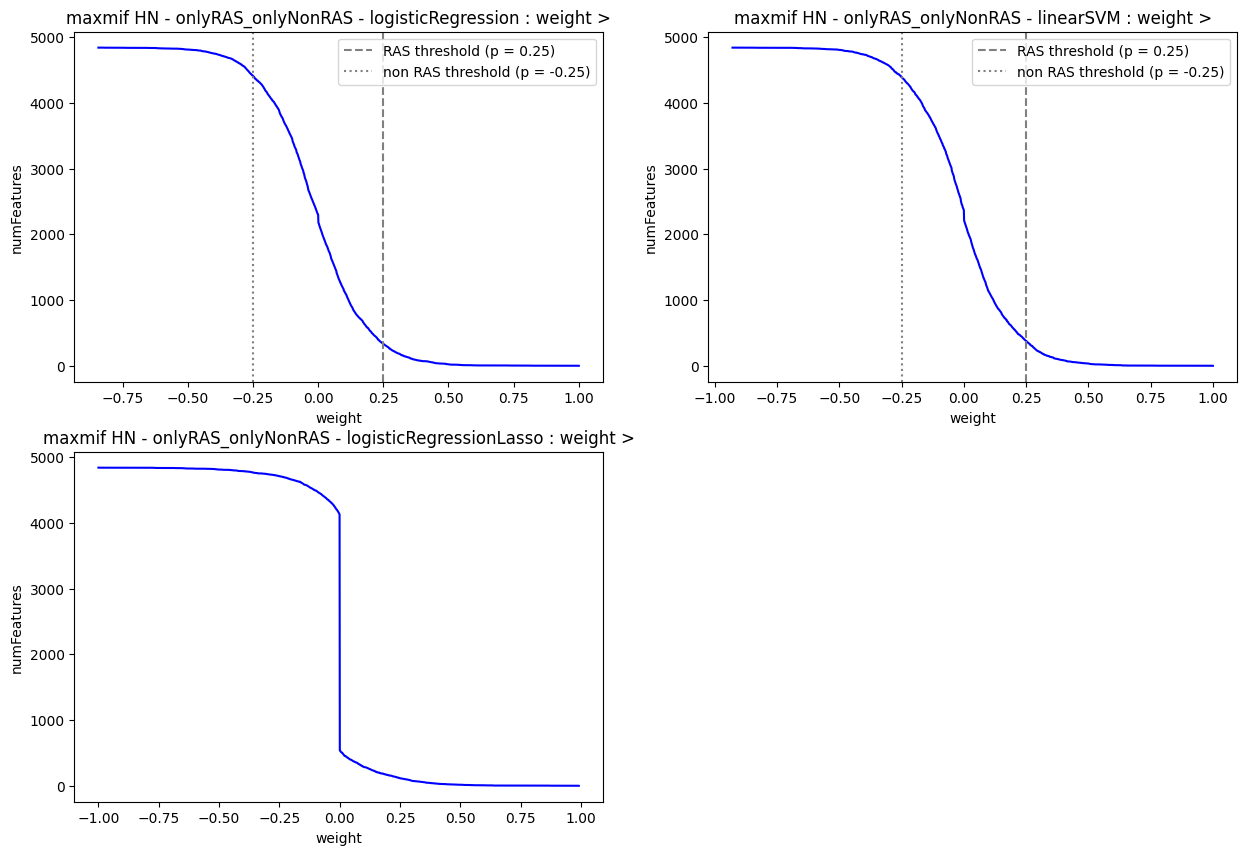

In [36]:
# plot both in different plots
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
ax = ax.flatten()

ax[0].plot(plot_LR_maxmifHN_oncodriveclustl['weight'], plot_LR_maxmifHN_oncodriveclustl['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--', label='RAS threshold (p = 0.25)')
ax[0].axvline(x=-0.25, color='grey', linestyle=':', label='non RAS threshold (p = -0.25)')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegression : weight >')
ax[0].legend()

ax[1].plot(plot_lSVM_maxmifHN_oncodriveclustl['weight'], plot_lSVM_maxmifHN_oncodriveclustl['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--', label='RAS threshold (p = 0.25)')
ax[1].axvline(x=-0.25, color='grey', linestyle=':', label='non RAS threshold (p = -0.25)')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('maxmif HN - onlyRAS_onlyNonRAS - linearSVM : weight >')
ax[1].legend()

ax[2].plot(plot_LRl_maxmifHN_oncodriveclustl['weight'], plot_LRl_maxmifHN_oncodriveclustl['numFeatures'], color='blue')
# ax[2].axvline(x=0.1, color='grey', linestyle='--')
# ax[2].axvline(x=-0.04, color='grey', linestyle=':')
ax[2].set_xlabel('weight')
ax[2].set_ylabel('numFeatures')
ax[2].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegressionLasso : weight >')

ax[3].axis('off')

# set title
# plt.suptitle('maxmif HN - onlyRAS_onlyNonRAS - oncodriveclustl')

plt.savefig('data/plots/fia/w_oncodriveclustl_thresholds.png')

#### significant features

In [37]:
RAS_significantFeatures_LR_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LR weight'] > 0.25]['feature'])
RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['lSVM weight'] > 0.25]['feature'])
RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LRl weight'] > 0]['feature'])

len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl), len(RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl)

(334, 379, 539)

In [38]:
print("LR & lSVM:\t\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 307
LR & LRl:		 295
lSVM & LRl:		 314
LR & lSVM & LRl:	 277


In [39]:
nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LR weight'] < -0.25]['feature'])
nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['lSVM weight'] < -0.25]['feature'])
nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LRl weight'] < 0]['feature'])
len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl), len(nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl), len(nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl)

(431, 445, 720)

In [40]:
print("LR & lSVM:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 394
LR & LRl:		 371
lSVM & LRl:		 379
LR & lSVM & LRl:	 343


#### RAS-significant transcriptomic features

In [41]:
RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_oncodriveclustl 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl), len(RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl)

(195, 205, 277)

In [42]:
print("LR & lSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 173
LR & LRl:		 164
lSVM & LRl:		 169
LR & lSVM & LRl:	 151


In [43]:
importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['feature'].isin(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR weight,LRl weight,lSVM weight,sum
1,HOXB7_tran,HOXB7,RAS,0.908091,0.990180,1.000000,1.000000
2,HOXB3_tran,HOXB3,nonRAS,0.819105,0.924901,0.882283,0.906157
4,KCNN4_tran,KCNN4,nonRAS,0.733430,0.871139,0.738346,0.808384
3,DGKG_tran,DGKG,nonRAS,0.780992,0.627948,0.772515,0.752675
6,ZP2_tran,ZP2,nonRAS,0.606217,0.580975,0.656084,0.635992
...,...,...,...,...,...,...,...
219,CPS1_tran,CPS1,nonRAS,0.292528,0.006077,0.287236,0.202135
225,CEACAM1_tran,CEACAM1,nonRAS,0.289230,0.027520,0.267081,0.201441
328,MPRIP_tran,MPRIP,RAS,0.252504,0.046659,0.270815,0.196661
303,GLUL_tran,GLUL,nonRAS,0.260606,0.047313,0.255706,0.194469


#### RAS-significant mutational features

In [44]:
RAS_significantMutations_LR_maxmifHN_oncodriveclustl  = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl  = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_LRl_maxmifHN_oncodriveclustl  = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl), len(RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantMutations_LRl_maxmifHN_oncodriveclustl)

(139, 174, 262)

In [45]:
print("LR & lSVM:\t\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 134
LR & LRl:		 131
lSVM & LRl:		 145
LR & lSVM & LRl:	 126


In [46]:
importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['feature'].isin(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR weight,LRl weight,lSVM weight,sum
0,TFRC_noCluster,TFRC,nonRAS,1.000000,0.839077,0.613984,0.846388
9,NLRP12_noCluster,NLRP12,nonRAS,0.560616,0.549807,0.631449,0.601004
12,PAN2_noCluster,PAN2,nonRAS,0.547070,0.507016,0.637148,0.583532
32,GABRB1_noCluster,GABRB1,nonRAS,0.480440,0.487788,0.599341,0.540863
20,IL10RA_noCluster,IL10RA,RAS,0.502887,0.556386,0.508251,0.540848
...,...,...,...,...,...,...,...
318,RAB6B_noCluster,RAB6B,RAS,0.256022,0.013107,0.320169,0.203328
240,UBE2G2_noCluster,UBE2G2,nonRAS,0.282302,0.041675,0.264758,0.203133
306,ARPP21_noCluster,ARPP21,nonRAS,0.259893,0.049285,0.277513,0.202428
294,ITGAD_noCluster,ITGAD,nonRAS,0.263571,0.019759,0.275488,0.192811


#### comparison with maxmif significance in RAS/nonRAS

In [47]:
RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_LR_maxmifHN_oncodriveclustl
])
RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl
])
RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f)
    for f in RAS_significantMutations_LRl_maxmifHN_oncodriveclustl
])
len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl), len(RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl)

(138, 172, 259)

In [48]:
print("LR & lSVM:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 133
LR & LRl:		 130
lSVM & LRl:		 143
LR & lSVM & LRl:	 125


In [49]:
nonRAS_significantMutations_LR_maxmifHN_oncodriveclustl  = set([
    f for f in nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_lSVM_maxmifHN_oncodriveclustl  = set([
    f for f in nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_LRl_maxmifHN_oncodriveclustl  = set([
    f for f in nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LR_maxmifHN_oncodriveclustl
])
nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_lSVM_maxmifHN_oncodriveclustl
])
nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LRl_maxmifHN_oncodriveclustl
])

len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl), len(nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl), len(nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl)

(235, 251, 401)

In [50]:
print("LR & lSVM:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 219
LR & LRl:		 204
lSVM & LRl:		 213
LR & lSVM & LRl:	 192


In [51]:
# LR: RAS -> RAS
odc_LR_RAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyRAS]
# LR: nonRAS -> RAS
odc_LR_nonRAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyNonRAS]
# LR: RAS -> nonRAS
odc_LR_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyRAS]
# LR: nonRAS -> nonRAS
odc_LR_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyNonRAS]
len(odc_LR_RAS_RAS), len(odc_LR_nonRAS_RAS), len(odc_LR_RAS_nonRAS), len(odc_LR_nonRAS_nonRAS)

(54, 84, 3, 232)

In [52]:
# lSVM: RAS -> RAS
odc_lSVM_RAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyRAS]
# lSVM: nonRAS -> RAS
odc_lSVM_nonRAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyNonRAS]
# lSVM: RAS -> nonRAS
odc_lSVM_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyRAS]
# lSVM: nonRAS -> nonRAS
odc_lSVM_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyNonRAS]
len(odc_lSVM_RAS_RAS), len(odc_lSVM_nonRAS_RAS), len(odc_lSVM_RAS_nonRAS), len(odc_lSVM_nonRAS_nonRAS)

(65, 107, 4, 247)

In [53]:
# LRl: RAS -> RAS
odc_LRl_RAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyRAS]
# LRl: nonRAS -> RAS
odc_LRl_nonRAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyNonRAS]
# LRl: RAS -> nonRAS
odc_LRl_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyRAS]
# LRl: nonRAS -> nonRAS
odc_LRl_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyNonRAS]
len(odc_LRl_RAS_RAS), len(odc_LRl_nonRAS_RAS), len(odc_LRl_RAS_nonRAS), len(odc_LRl_nonRAS_nonRAS)

(97, 162, 13, 388)

#### RAS-significant mutational clustered features

In [54]:
RAS_significantClusters_LR_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantMutations_LR_maxmifHN_oncodriveclustl
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_LRl_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantMutations_LRl_maxmifHN_oncodriveclustl
    if re.search(r'_\d+_\d+', f) 
])

len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl), len(RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantClusters_LRl_maxmifHN_oncodriveclustl)

(22, 24, 40)

In [55]:
print("LR & lSVM:\t\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 22
LR & LRl:		 21
lSVM & LRl:		 22
LR & lSVM & LRl:	 21


In [56]:
importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['feature'].isin(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR weight,LRl weight,lSVM weight,sum
5,EML5_89124580_89124582,EML5,nonRAS,0.611318,0.224764,0.633787,0.507154
37,ATAD5_29161567_29161578,ATAD5,nonRAS,0.461342,0.344545,0.520521,0.457655
14,COPS4_83984313_83984315,COPS4,nonRAS,0.542089,0.186142,0.576807,0.450281
60,SLC2A14_7981303_7981308,SLC2A14,RAS,0.427598,0.398201,0.475803,0.449096
63,UBXN4_136513160_136513161,UBXN4,nonRAS,0.423760,0.404362,0.439150,0.437251
30,RAMP3_45222982_45222997,RAMP3,RAS,0.489467,0.152116,0.599358,0.428166
82,SLC6A2_55729219_55729245,SLC6A2,nonRAS,0.383387,0.288953,0.412383,0.374266
101,CLTCL1_19223298_19223299,CLTCL1,nonRAS,0.363912,0.298462,0.381889,0.360306
118,LENG8_54967586_54967593,LENG8,RAS,0.351302,0.245737,0.431971,0.355043
115,KIRREL3_126333180_126333195,KIRREL3,nonRAS,0.353687,0.224321,0.408889,0.340512


significant clusters' genes

In [57]:
RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LR_maxmifHN_oncodriveclustl
])
RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl
])
RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LRl_maxmifHN_oncodriveclustl
])

len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl), len(RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl)

(22, 24, 40)

In [58]:
print("LR & lSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl))

LR & lSVM:		 22
LR & LRl:		 21
lSVM & LRl:		 22
LR & lSVM & LRl:	 21


## both

In [59]:
importance_maxmifHN = pd.merge(importance_maxmifHN_mutclust.drop(columns=['sum']), importance_maxmifHN_oncodriveclustl.drop(columns=['sum']), on=['feature', 'gene', 'from'], how='outer', suffixes=(' - mc', ' - odc'))

numerical_cols = importance_maxmifHN.select_dtypes(include=['number']).columns
importance_maxmifHN['sum'] = importance_maxmifHN[numerical_cols].sum(axis=1)
importance_maxmifHN[['sum']] = importance_maxmifHN[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN = importance_maxmifHN.sort_values('sum', ascending=False)

importance_maxmifHN

,feature,gene,from,LR weight - mc,LRl weight - mc,lSVM weight - mc,LR weight - odc,LRl weight - odc,lSVM weight - odc,sum
1924,HOXB7_tran,HOXB7,RAS,0.859841,0.839301,1.000000,0.908091,0.990180,1.000000,1.000000
1922,HOXB3_tran,HOXB3,nonRAS,0.783165,0.761539,0.896918,0.819105,0.924901,0.882283,0.905402
4449,TFRC_noCluster,TFRC,nonRAS,1.000000,0.653211,0.831274,1.000000,0.839077,0.613984,0.882112
2152,KCNN4_tran,KCNN4,nonRAS,0.707630,1.000000,0.764205,0.733430,0.871139,0.738346,0.860174
1047,DGKG_tran,DGKG,nonRAS,0.757431,0.727984,0.829387,0.780992,0.627948,0.772515,0.803274
...,...,...,...,...,...,...,...,...,...,...
2801,NOD1_tran,NOD1,nonRAS,-0.613078,-0.576475,-0.635059,-0.614012,-0.772506,-0.580128,-0.677323
3207,PLEKHA4_tran,PLEKHA4,nonRAS,-0.627557,-0.474324,-0.702809,-0.651971,-0.682155,-0.668351,-0.680165
3691,RHEB_noCluster,RHEB,nonRAS,-0.723278,-0.285917,-0.829736,-0.740714,-1.000000,-0.802174,-0.782829
712,CEP350_noCluster,CEP350,nonRAS,-0.817405,-0.734700,-0.931176,-0.821188,-0.511439,-0.867052,-0.836629


#### RAS-significant transcriptomic features

In [60]:
RAS_significantTranscriptomic_LR_maxmifHN = RAS_significantTranscriptomic_LR_maxmifHN_mutclust & RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl
RAS_significantTranscriptomic_lSVM_maxmifHN = RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl
RAS_significantTranscriptomic_LRl_maxmifHN = RAS_significantTranscriptomic_LRl_maxmifHN_mutclust & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl
len(RAS_significantTranscriptomic_LR_maxmifHN), len(RAS_significantTranscriptomic_lSVM_maxmifHN), len(RAS_significantTranscriptomic_LRl_maxmifHN)

(184, 199, 168)

In [61]:
print("LR & lSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN & RAS_significantTranscriptomic_lSVM_maxmifHN))
print("LR & LRl:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN & RAS_significantTranscriptomic_LRl_maxmifHN))
print("lSVM & LRl:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN & RAS_significantTranscriptomic_LRl_maxmifHN))

print("LR & lSVM & LRl:\t", len(RAS_significantTranscriptomic_LR_maxmifHN & RAS_significantTranscriptomic_lSVM_maxmifHN & RAS_significantTranscriptomic_LRl_maxmifHN))

LR & lSVM:		 167
LR & LRl:		 131
lSVM & LRl:		 133
LR & lSVM & LRl:	 124


In [62]:
importance_maxmifHN[importance_maxmifHN['feature'].isin(RAS_significantTranscriptomic_LR_maxmifHN & RAS_significantTranscriptomic_lSVM_maxmifHN & RAS_significantTranscriptomic_LRl_maxmifHN)]

,feature,gene,from,LR weight - mc,LRl weight - mc,lSVM weight - mc,LR weight - odc,LRl weight - odc,lSVM weight - odc,sum
1924,HOXB7_tran,HOXB7,RAS,0.859841,0.839301,1.000000,0.908091,0.990180,1.000000,1.000000
1922,HOXB3_tran,HOXB3,nonRAS,0.783165,0.761539,0.896918,0.819105,0.924901,0.882283,0.905402
2152,KCNN4_tran,KCNN4,nonRAS,0.707630,1.000000,0.764205,0.733430,0.871139,0.738346,0.860174
1047,DGKG_tran,DGKG,nonRAS,0.757431,0.727984,0.829387,0.780992,0.627948,0.772515,0.803274
5044,ZP2_tran,ZP2,nonRAS,0.609679,0.381681,0.707931,0.606217,0.580975,0.656084,0.632894
...,...,...,...,...,...,...,...,...,...,...
695,CEACAM1_tran,CEACAM1,nonRAS,0.283347,0.037127,0.289365,0.289230,0.027520,0.267081,0.213254
3473,PTPN3_tran,PTPN3,nonRAS,0.266230,0.015350,0.270162,0.283868,0.070886,0.271039,0.210371
1687,GOLGA2_tran,GOLGA2,nonRAS,0.269112,0.001376,0.296227,0.293102,0.017010,0.292192,0.208850
3590,RASA2_tran,RASA2,RAS,0.254917,0.018985,0.276765,0.267416,0.068191,0.270558,0.206672


#### RAS-significant mutated gens

In [63]:
RAS_significantMutations_LR_maxmifHN = RAS_significantMutGenes_LR_maxmifHN_mutclust & RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl
RAS_significantMutGenes_lSVM_maxmifHN = RAS_significantMutGenes_lSVM_maxmifHN_mutclust & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl
RAS_significantMutGenes_LRl_maxmifHN = RAS_significantMutGenes_LRl_maxmifHN_mutclust & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl
len(RAS_significantMutations_LR_maxmifHN), len(RAS_significantMutGenes_lSVM_maxmifHN), len(RAS_significantMutGenes_LRl_maxmifHN)

(106, 147, 158)

In [64]:
print("LR & lSVM:\t\t", len(RAS_significantMutations_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN))
print("LR & LRl:\t\t", len(RAS_significantMutations_LR_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN))
print("lSVM & LRl:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN))

print("LR & lSVM & LRl:\t", len(RAS_significantMutations_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN))

LR & lSVM:		 102
LR & LRl:		 96
lSVM & LRl:		 112
LR & lSVM & LRl:	 92


In [65]:
importance_maxmifHN[importance_maxmifHN['feature'].str.contains(r'(?:_noCluster|_\d+_\d+)$', regex=True) & importance_maxmifHN['gene'].isin(RAS_significantMutations_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN)]

,feature,gene,from,LR weight - mc,LRl weight - mc,lSVM weight - mc,LR weight - odc,LRl weight - odc,lSVM weight - odc,sum
4449,TFRC_noCluster,TFRC,nonRAS,1.000000,0.653211,0.831274,1.000000,0.839077,0.613984,0.882112
2788,NLRP12_noCluster,NLRP12,nonRAS,0.580424,0.394544,0.688288,0.560616,0.549807,0.631449,0.608340
2991,PAN2_noCluster,PAN2,nonRAS,0.521311,0.272349,0.655222,0.547070,0.507016,0.637148,0.560994
2009,IL10RA_noCluster,IL10RA,RAS,0.539077,0.400165,0.585856,0.502887,0.556386,0.508251,0.552509
4372,TAGAP_noCluster,TAGAP,RAS,0.518426,0.550244,0.639720,0.444553,0.374373,0.525356,0.545372
...,...,...,...,...,...,...,...,...,...,...
1526,FUS_228_229,FUS,RAS,0.025580,0.000000,0.020527,NaN,NaN,NaN,0.008237
4371,TAGAP_709_716,TAGAP,RAS,0.020313,0.000000,0.017253,NaN,NaN,NaN,0.006711
1511,FRMD4A_1005_1005,FRMD4A,RAS,-0.075342,0.000000,-0.042382,NaN,NaN,NaN,-0.021032
2694,NCOA5_21_28,NCOA5,nonRAS,-0.383718,-0.239976,-0.432735,NaN,NaN,NaN,-0.188735


In [66]:
'TNFSF11' in (RAS_significantMutations_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN)

True

In [67]:
import requests

def filter_hugo_symbols(hugo_symbols):
    found_symbols = []
    base_url = "https://idrblab.net/ttd/search/ttd/target?search_api_fulltext="
    
    for symbol in hugo_symbols:
        url = base_url + symbol
        try:
            response = requests.get(url)
            response.raise_for_status()  # Raises an HTTPError if the HTTP request returned an unsuccessful status code
            if "Sorry! Nothing is found" not in response.text:
                found_symbols.append(symbol)
        except requests.exceptions.RequestException as e:
            print(f"Error fetching data for symbol {symbol}: {e}")
    
    return found_symbols

In [68]:
gg = RAS_significantMutations_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN

In [69]:
# filter_hugo_symbols(gg)

In [70]:
['IFNAR2',
 'GPR39',
 'KY',
 'RXFP1',
 'SGK1',
 'CRP',
 'GDNF',
 'TNFSF11',
 'TUBB2A',
 'CTSL',
 'GALT',
 'RAMP3',
 'LGALS1',
 'ASIC2',
 'FECH',
 'FUS',
 'FGF23',
 'TFRC',
 'ARRB2',
 'HRH2',
 'TESK1']

['IFNAR2',
 'GPR39',
 'KY',
 'RXFP1',
 'SGK1',
 'CRP',
 'GDNF',
 'TNFSF11',
 'TUBB2A',
 'CTSL',
 'GALT',
 'RAMP3',
 'LGALS1',
 'ASIC2',
 'FECH',
 'FUS',
 'FGF23',
 'TFRC',
 'ARRB2',
 'HRH2',
 'TESK1']

TNFSF11:
- **ACTIONABLE** - Successful target
- may have a role in the regulation of cell apoptosis
- ligand for osteoprotegerin and functions as a key factor for osteoclast differentiation and activation

#### RAS-significant cluster's genes

In [71]:
RAS_significantClusterGenes_LR_maxmifHN = RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl
RAS_significantClusterGenes_lSVM_maxmifHN = RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl
RAS_significantClusterGenes_LRl_maxmifHN = RAS_significantClusterGenes_LRl_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl
len(RAS_significantClusterGenes_LR_maxmifHN), len(RAS_significantClusterGenes_lSVM_maxmifHN), len(RAS_significantClusterGenes_LRl_maxmifHN)

(3, 4, 6)

In [72]:
print("LR & lSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_lSVM_maxmifHN))
print("LR & LRl:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN))
print("lSVM & LRl:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN))

print("LR & lSVM & LRl:\t", len(RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_lSVM_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN))

LR & lSVM:		 3
LR & LRl:		 3
lSVM & LRl:		 4
LR & lSVM & LRl:	 3


In [73]:
importance_maxmifHN[importance_maxmifHN['feature'].str.contains(r'(?:_\d+_\d+)$', regex=True) & importance_maxmifHN['gene'].isin(RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN)].sort_values('gene', ascending=False)

,feature,gene,from,LR weight - mc,LRl weight - mc,lSVM weight - mc,LR weight - odc,LRl weight - odc,lSVM weight - odc,sum
1937,HRH2_175110302_175110303,HRH2,nonRAS,NaN,NaN,NaN,0.383426,0.048784,0.412801,0.150964
1938,HRH2_22_23,HRH2,nonRAS,0.270283,0.096473,0.295143,NaN,NaN,NaN,0.118251
850,COPS4_83984313_83984315,COPS4,nonRAS,NaN,NaN,NaN,0.542089,0.186142,0.576807,0.233150
849,COPS4_267_268,COPS4,nonRAS,0.459063,0.107876,0.511380,NaN,NaN,NaN,0.192646
351,ATAD5_1505_1506,ATAD5,nonRAS,0.461472,0.443431,0.567927,NaN,NaN,NaN,0.263127
352,ATAD5_29161567_29161578,ATAD5,nonRAS,NaN,NaN,NaN,0.461342,0.344545,0.520521,0.236968


## Graphs

#### data composition

In [74]:
trans_mutclust = set([
    f for f in importance_maxmifHN_mutclust['feature'] 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
cluster_mutclust = set([
    f for f in importance_maxmifHN_mutclust['feature'] 
    if re.search(r'_\d+_\d+', f)
])
noCluster_mutclust = set([
    f for f in importance_maxmifHN_mutclust['feature'] 
    if '_noCluster' in f
])

trans_oncodriveclustl = set([
    f for f in importance_maxmifHN_oncodriveclustl['feature'] 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
cluster_oncodriveclustl = set([
    f for f in importance_maxmifHN_oncodriveclustl['feature'] 
    if re.search(r'_\d+_\d+', f)
])
noCluster_oncodriveclustl = set([
    f for f in importance_maxmifHN_oncodriveclustl['feature'] 
    if '_noCluster' in f
])

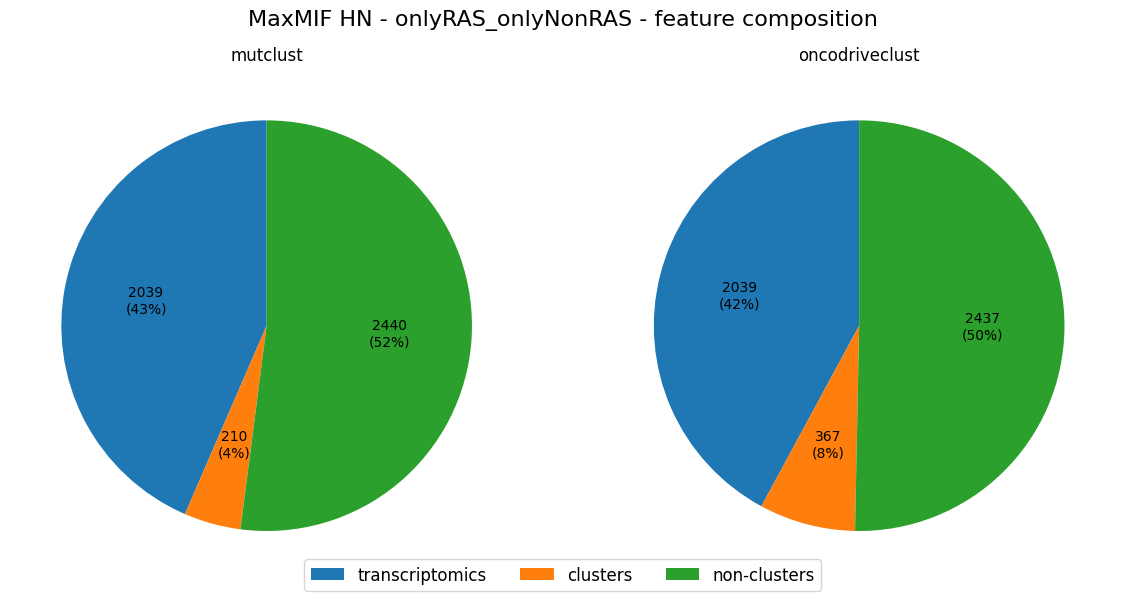

In [83]:
data = [
    [trans_mutclust, cluster_mutclust, noCluster_mutclust], 
    [trans_oncodriveclustl, cluster_oncodriveclustl, noCluster_oncodriveclustl]
]
data = [[len(i[0]), len(i[1]), len(i[2])] for i in data]

fig_title = 'MaxMIF HN - onlyRAS_onlyNonRAS - feature composition'
titles = ['mutclust', 'oncodriveclust']
labels = ['transcriptomics', 'clusters', 'non-clusters']

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle(fig_title, fontsize=16)

for i, ax in enumerate(axes.flat):
    counts = data[i]
    total = sum(counts)
    
    # Create pie chart with percentage-only labels first
    wedges, texts, autotexts = ax.pie(
        counts, 
        autopct='%1.0f%%',  # Temporary placeholder
        startangle=90
    )
    ax.set_title(titles[i])
    
    # Update autotexts to show raw counts + percentages
    for j, txt in enumerate(autotexts):
        count = counts[j]
        percentage = (count / total) * 100
        txt.set_text(f"{count}\n({percentage:.0f}%)")  # New line for clarity

# Add legend
fig.legend(
    handles=wedges,
    labels=labels,
    loc='lower center',
    ncol=3,
    fontsize=12
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('data/plots/fia/featureComposition.png')
plt.show()

#### comparison of mutation relevant for RAS/nonRAS prediction with maxmif significant in classes RAS/nonRAS

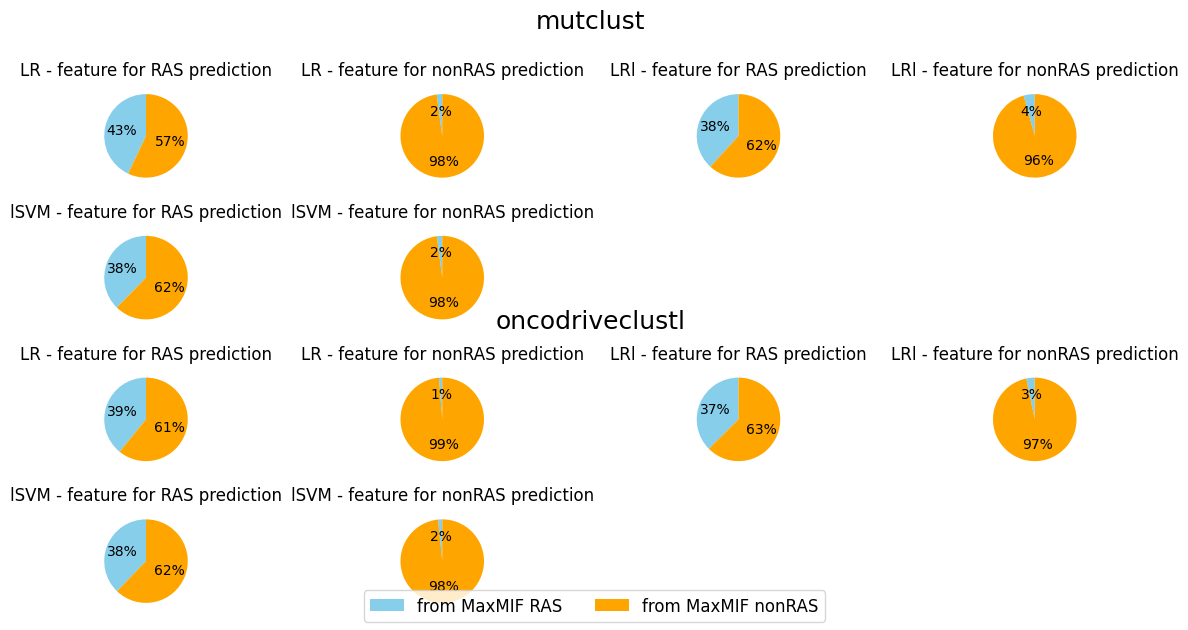

In [84]:
data = [
    [mc_LR_RAS_RAS, mc_LR_nonRAS_RAS], [mc_LR_RAS_nonRAS, mc_LR_nonRAS_nonRAS],
    [mc_LRl_RAS_RAS, mc_LRl_nonRAS_RAS], [mc_LRl_RAS_nonRAS, mc_LRl_nonRAS_nonRAS],
    [mc_lSVM_RAS_RAS, mc_lSVM_nonRAS_RAS], [mc_lSVM_RAS_nonRAS, mc_lSVM_nonRAS_nonRAS],
    [[],[]], [[], []],
    [odc_LR_RAS_RAS, odc_LR_nonRAS_RAS], [odc_LR_RAS_nonRAS, odc_LR_nonRAS_nonRAS],
    [odc_LRl_RAS_RAS, odc_LRl_nonRAS_RAS], [odc_LRl_RAS_nonRAS, odc_LRl_nonRAS_nonRAS],
    [odc_lSVM_RAS_RAS, odc_lSVM_nonRAS_RAS], [odc_lSVM_RAS_nonRAS, odc_lSVM_nonRAS_nonRAS],
    [[],[]], [[], []]
]
data = [[len(i[0]), len(i[1])] for i in data]


fig_title = 'MaxMIF HN - onlyRAS_onlyNonRAS'

titles = [
    'LR - feature for RAS prediction', 'LR - feature for nonRAS prediction',
    'LRl - feature for RAS prediction', 'LRl - feature for nonRAS prediction',
    'lSVM - feature for RAS prediction', 'lSVM - feature for nonRAS prediction',
    '', '',
    'LR - feature for RAS prediction', 'LR - feature for nonRAS prediction',
    'LRl - feature for RAS prediction', 'LRl - feature for nonRAS prediction',
    'lSVM - feature for RAS prediction', 'lSVM - feature for nonRAS prediction',
    '', ''
]

row_titles = ['mutclust', 'oncodriveclustl']

labels = ['from MaxMIF RAS', 'from MaxMIF nonRAS']
colors = ['skyblue', 'orange']

fig, axes = plt.subplots(4, 4, figsize=(12, 6))

# fig.suptitle(fig_title, fontsize=16)

for row, title in enumerate(row_titles):
    fig.text(0.5, 1 - (row * 0.5), title, ha='center', fontsize=18)

for i, ax in enumerate(axes.flat):
    if data[i] != [0,0]:
        wedges, texts, autotexts = ax.pie(data[i], colors=colors, autopct='%1.0f%%', startangle=90)
        ax.set_title(titles[i])
    else:
        ax.axis('off')

fig.legend(
    handles=wedges,  # Use wedges from the last subplot
    labels=labels,  # Labels for the legend
    loc='lower center',  # Position at the top
    ncol=2,  # Arrange legend in two columns
    fontsize=12,  # Font size for the legend
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('data/plots/fia/w_fromRASorNonRAS.png', bbox_inches='tight')
plt.show()

#### RAS - venn - transcriptomics and mutation genes

In [77]:
RAS_significantTranscriptomicGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LR_maxmifHN_mutclust
])

RAS_significantTranscriptomicGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust
])

RAS_significantTranscriptomicGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LRl_maxmifHN_mutclust
])

RAS_significantTranscriptomicGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl
])

RAS_significantTranscriptomicGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl
])

RAS_significantTranscriptomicGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl
])

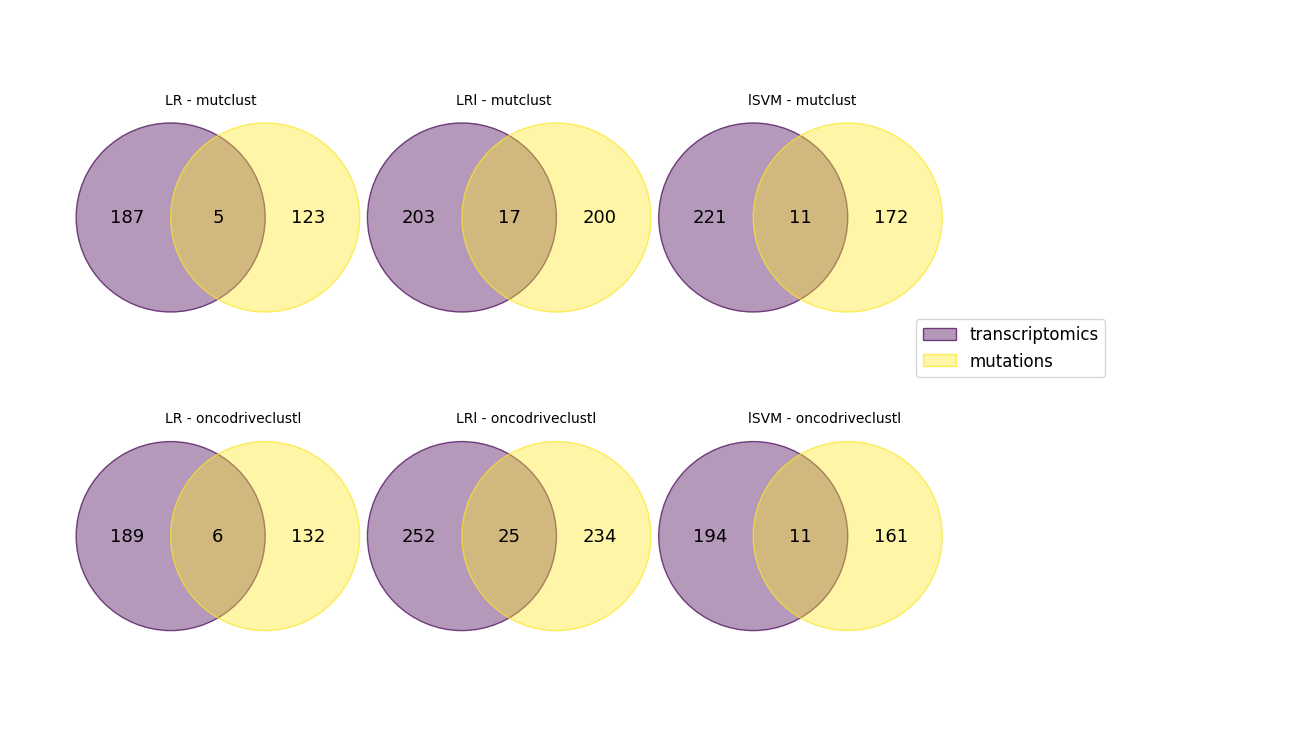

In [78]:
venn_data = [
    {'transcriptomics': RAS_significantTranscriptomicGenes_LR_maxmifHN_mutclust, 'mutations': RAS_significantMutGenes_LR_maxmifHN_mutclust},
    {'transcriptomics': RAS_significantTranscriptomicGenes_LRl_maxmifHN_mutclust, 'mutations': RAS_significantMutGenes_LRl_maxmifHN_mutclust},
    {'transcriptomics':  RAS_significantTranscriptomicGenes_lSVM_maxmifHN_mutclust, 'mutations': RAS_significantMutGenes_lSVM_maxmifHN_mutclust},
    
    {'transcriptomics': RAS_significantTranscriptomicGenes_LR_maxmifHN_oncodriveclustl, 'mutations': RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl},
    {'transcriptomics': RAS_significantTranscriptomicGenes_LRl_maxmifHN_oncodriveclustl, 'mutations': RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl},
    {'transcriptomics':  RAS_significantTranscriptomicGenes_lSVM_maxmifHN_oncodriveclustl, 'mutations': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl}
]

titles = ['LR - mutclust', 'LRl - mutclust', 'lSVM - mutclust', 'LR - oncodriveclustl', 'LRl - oncodriveclustl', 'lSVM - oncodriveclustl']

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    venn(venn_data[i], ax=ax)
    ax.get_legend().set_visible(False)
    # ax.set_title(titles[i], fontsize=10, loc='center', pad=-20)
    ax.annotate(titles[i], xy=(0.36, 0.8), fontsize=10)

fig.legend(
    ['transcriptomics', 'mutations'],  # Legend labels for the sets
    loc=(0.7, 0.5),#'center right',  # Position at the top
    ncol=1,  # Arrange legend items in two columns
    fontsize=12  # Font size for the legend
)

plt.tight_layout(pad=-7, rect=[0, 0, 0.6, 0.9])
plt.savefig('data/plots/fia/w_tranAndMut.png')
plt.show()

#### RAS - venn - LR and lSVM mutation genes

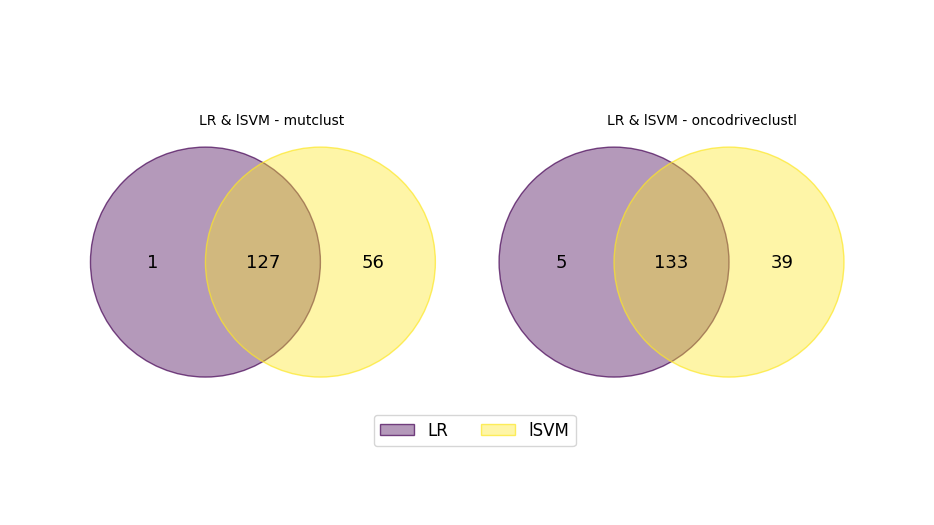

In [79]:
venn_data = [
    {'LR': RAS_significantMutGenes_LR_maxmifHN_mutclust, 'lSVM': RAS_significantMutGenes_lSVM_maxmifHN_mutclust},
    {'LR':  RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl, 'lSVM': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl},
]

titles = ['LR & lSVM - mutclust', 'LR & lSVM - oncodriveclustl']

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    venn(venn_data[i], ax=ax)
    ax.get_legend().set_visible(False)
    # ax.set_title(titles[i], fontsize=10, loc='center', pad=-20)
    ax.annotate(titles[i], xy=(0.36, 0.8), fontsize=10)

fig.legend(
    ['LR', 'lSVM'],  # Legend labels for the sets
    loc=(0.4, 0.15),#'center right',  # Position at the top
    ncol=2,  # Arrange legend items in two columns
    fontsize=12  # Font size for the legend
)

plt.tight_layout(pad=-7, rect=[0, 0, 0.6, 0.9])

plt.show()

#### RAS - venn - mutclust and oncodriveclustl mutation genes

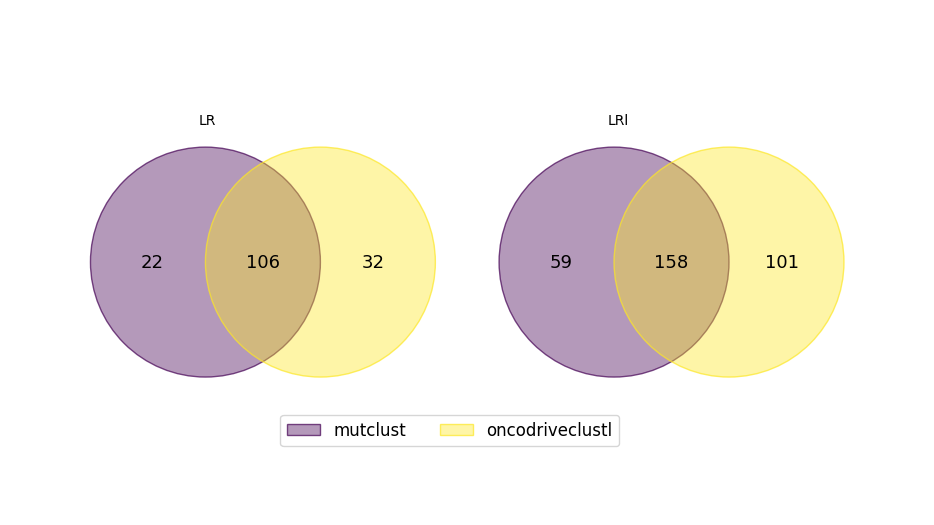

In [80]:
venn_data = [
    {'mutclust': RAS_significantMutGenes_LR_maxmifHN_mutclust, 'oncodriveclustl': RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl},
    {'mutclust': RAS_significantMutGenes_LRl_maxmifHN_mutclust, 'oncodriveclustl': RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl},
    {'mutclust': RAS_significantMutGenes_lSVM_maxmifHN_mutclust, 'oncodriveclustl': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl},
]

titles = ['LR', 'LRl', 'lSVM']

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    venn(venn_data[i], ax=ax)
    ax.get_legend().set_visible(False)
    # ax.set_title(titles[i], fontsize=10, loc='center', pad=-20)
    ax.annotate(titles[i], xy=(0.36, 0.8), fontsize=10)

fig.legend(
    ['mutclust', 'oncodriveclustl'],  # Legend labels for the sets
    loc=(0.3, 0.15),#'center right',  # Position at the top
    ncol=2,  # Arrange legend items in two columns
    fontsize=12  # Font size for the legend
)

plt.tight_layout(pad=-7, rect=[0, 0, 0.6, 0.9])

plt.show()

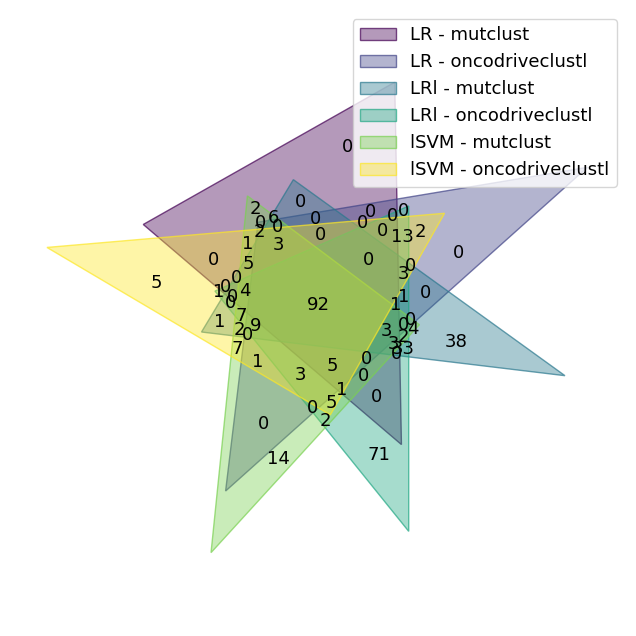

In [81]:
venn({
    'LR - mutclust': RAS_significantMutGenes_LR_maxmifHN_mutclust, 'LR - oncodriveclustl': RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl,
    'LRl - mutclust': RAS_significantMutGenes_LRl_maxmifHN_mutclust, 'LRl - oncodriveclustl': RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl,
    'lSVM - mutclust': RAS_significantMutGenes_lSVM_maxmifHN_mutclust, 'lSVM - oncodriveclustl': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl,
})

plt.savefig('data/plots/fia/w_mutGenes_allIntersection.png')